In [ ]:
# SOCIAL MEDIA ENGAGEMENT ANALYTICS

**Python for Data Analysis**

---

## 01 | PROJECT INTRODUCTION

### 1.1 Problem Statement

Social media platforms generate huge amounts of data every day through user interactions such as likes, comments, shares, impressions, and watch time. Understanding this data is important for businesses and organizations to measure their online performance and improve audience engagement.

However, analyzing large volumes of social media data manually can be challenging. Without proper analysis, it becomes difficult to identify popular content, understand audience preferences, measure engagement levels, and determine which factors influence post performance.

This project focuses on analyzing social media engagement data using Python to discover meaningful patterns, identify trends, and generate valuable insights that can help improve social media content strategies and decision-making.

### 1.2 Project Objectives

The main objectives of this project are:

- Analyze social media engagement metrics such as likes, comments, shares, and impressions.
- Identify high-performing post types and content categories.
- Examine audience demographics and engagement patterns.
- Understand the relationship between impressions and engagement.
- Analyze sentiment and device-based engagement.
- Identify trends and patterns in social media interactions.
- Develop actionable, data-driven business recommendations.

### 1.3 Analytical Approach

This project follows a structured data analytics workflow to transform raw social media data into meaningful business insights.

**Data Collection → Data Cleaning → Data Transformation → Exploratory Data Analysis → Statistical Analysis → Data Visualization → Business Insights**

Each stage helps ensure that

# Task 1 — Data Import & Setup

In [8]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Task 1 — Data Import & Setup

In [15]:
# Load the dataset

df = pd.read_csv(r"C:\Users\Hanna Farook\Downloads\social_media_engagement_5000.csv")

In [16]:
df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372


In [17]:
df.shape

(5000, 19)

In [18]:
df.columns

Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate'],
      dtype='str')

In [19]:
df.tail()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
4995,59500,44.0,Male,Australia,441541,video,education,16210.0,2013.0,1837.0,6190,42977,25-06-2022,646147,False,mobile,positive,#travel #fun,0.466761
4996,22100,38.0,Other,UAE,677076,reel,education,16924.0,2734.0,1583.0,7764,34196,18-11-2022,584603,False,desktop,negative,#foodie #reels,0.621155
4997,67021,63.0,Female,USA,273595,text,travel,13487.0,NaN,167.0,7466,23680,06-04-2023,483550,False,desktop,positive,#lifestyle #tech,0.679688
4998,29800,13.0,Female,Germany,785644,video,fitness,16894.0,1289.0,1713.0,4991,89013,16-05-2022,183295,False,tablet,positive,#reels #love #fitness,0.223518
4999,73400,54.0,Other,Japan,712252,text,travel,14830.0,503.0,1798.0,3743,14234,04-03-2023,585760,False,desktop,neutral,#foodie #lifestyle #fashion,1.203527


In [20]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   user_id           5000 non-null   int64  
 1   age               4850 non-null   float64
 2   gender            4850 non-null   str    
 3   country           5000 non-null   str    
 4   post_id           5000 non-null   int64  
 5   post_type         5000 non-null   str    
 6   post_category     5000 non-null   str    
 7   likes             4850 non-null   float64
 8   comments          4850 non-null   float64
 9   shares            4850 non-null   float64
 10  watch_time_sec    5000 non-null   int64  
 11  impression_count  5000 non-null   int64  
 12  posted_at         5000 non-null   str    
 13  follower_count    5000 non-null   int64  
 14  is_verified       5000 non-null   bool   
 15  device_type       5000 non-null   str    
 16  sentiment         4850 non-null   str    
 17  hashta

In [21]:
df.dtypes

user_id               int64
age                 float64
gender                  str
country                 str
post_id               int64
post_type               str
post_category           str
likes               float64
comments            float64
shares              float64
watch_time_sec        int64
impression_count      int64
posted_at               str
follower_count        int64
is_verified            bool
device_type             str
sentiment               str
hashtags                str
engagement_rate     float64
dtype: object

In [22]:
#Convert date columns to datetime
df['posted_at'] = pd.to_datetime(df['posted_at'], dayfirst=True)

df['posted_at'].head()

0   2022-12-17
1   2023-06-02
2   2023-05-07
3   2023-02-12
4   2023-05-23
Name: posted_at, dtype: datetime64[us]

In [23]:
#NumPy operations
likes_array = np.array(df['likes'].dropna())

print("Total Likes:", np.sum(likes_array))
print("Average Likes:", np.mean(likes_array))
print("Maximum Likes:", np.max(likes_array))
print("Minimum Likes:", np.min(likes_array))

Total Likes: 49019162.0
Average Likes: 10107.043711340206
Maximum Likes: 19998.0
Minimum Likes: 10.0


# Task 2 — Data Cleaning

In [24]:
df_clean = df.copy()

In [25]:
#Cleaning Missing Data
#Detect missing values
df_clean.isnull().sum()


user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
dtype: int64

In [28]:
#Handle missing numerical values
df_clean['age'] = df_clean['age'].fillna(df_clean['age'].median())

df_clean['likes'] = df_clean['likes'].fillna(df_clean['likes'].median())

df_clean['comments'] = df_clean['comments'].fillna(df_clean['comments'].median())

df_clean['shares'] = df_clean['shares'].fillna(df_clean['shares'].median())

In [29]:
#Handle missing categorical values
df_clean['gender'] = df_clean['gender'].fillna(df_clean['gender'].mode()[0])

df_clean['sentiment'] = df_clean['sentiment'].fillna(df_clean['sentiment'].mode()[0])

In [30]:
#Check missing values again
df_clean.isnull().sum()

user_id             0
age                 0
gender              0
country             0
post_id             0
post_type           0
post_category       0
likes               0
comments            0
shares              0
watch_time_sec      0
impression_count    0
posted_at           0
follower_count      0
is_verified         0
device_type         0
sentiment           0
hashtags            0
engagement_rate     0
dtype: int64

In [31]:
#Duplicate Handling
#Identify duplicates
df_clean.duplicated().sum()

np.int64(0)

In [32]:
#remove duplicates
df_clean = df_clean.drop_duplicates()

In [33]:
#Standardize categories
df_clean['gender'] = df_clean['gender'].str.strip().str.title()

df_clean['sentiment'] = df_clean['sentiment'].str.strip().str.lower()

df_clean['post_type'] = df_clean['post_type'].str.strip().str.lower()

df_clean['post_category'] = df_clean['post_category'].str.strip().str.lower()

df_clean['device_type'] = df_clean['device_type'].str.strip().str.lower()

df_clean['country'] = df_clean['country'].str.strip().str.title()


In [34]:
df_clean.dtypes

user_id                      int64
age                        float64
gender                         str
country                        str
post_id                      int64
post_type                      str
post_category                  str
likes                      float64
comments                   float64
shares                     float64
watch_time_sec               int64
impression_count             int64
posted_at           datetime64[us]
follower_count               int64
is_verified                   bool
device_type                    str
sentiment                      str
hashtags                       str
engagement_rate            float64
dtype: object

In [35]:
numeric_columns = [
    'user_id',
    'age',
    'post_id',
    'likes',
    'comments',
    'shares',
    'watch_time_sec',
    'impression_count',
    'follower_count',
    'engagement_rate'
]

for col in numeric_columns:
    df_clean[col] = pd.to_numeric(df_clean[col], errors='coerce')

In [36]:
df_clean['posted_at'] = pd.to_datetime(
    df_clean['posted_at'],
    format='%d-%m-%Y',
    errors='coerce'
)

In [37]:
integer_columns = [
    'user_id',
    'age',
    'post_id',
    'likes',
    'comments',
    'shares',
    'watch_time_sec',
    'impression_count',
    'follower_count'
]

for col in integer_columns:
    df_clean[col] = df_clean[col].astype('int64')

In [38]:
df_clean.dtypes

user_id                      int64
age                          int64
gender                         str
country                        str
post_id                      int64
post_type                      str
post_category                  str
likes                        int64
comments                     int64
shares                       int64
watch_time_sec               int64
impression_count             int64
posted_at           datetime64[us]
follower_count               int64
is_verified                   bool
device_type                    str
sentiment                      str
hashtags                       str
engagement_rate            float64
dtype: object

In [39]:
#Correct unrealistic values
print("Negative Likes:", (df_clean['likes'] < 0).sum())

print("Negative Comments:", (df_clean['comments'] < 0).sum())

print("Negative Shares:", (df_clean['shares'] < 0).sum())

Negative Likes: 0
Negative Comments: 0
Negative Shares: 0


In [40]:
columns = ['likes', 'comments', 'shares']

for col in columns:
    df_clean.loc[df_clean[col] < 0, col] = 0

In [42]:
#Extract hashtag count
df_clean['hashtag_count'] = df_clean['hashtags'].str.findall(r'#\w+').str.len()
df_clean[['hashtags', 'hashtag_count']].head(10)
df_clean['sentiment'] = df_clean['sentiment'].str.strip().str.lower()
df_clean['sentiment'].unique()
print("Dataset Shape:")
print(df_clean.shape)

print("\nMissing Values:")
print(df_clean.isnull().sum())

print("\nDuplicate Rows:")
print(df_clean.duplicated().sum())

print("\nData Types:")
print(df_clean.dtypes)

print("\nCleaned Dataset:")
display(df_clean.head())

Dataset Shape:
(5000, 20)

Missing Values:
user_id             0
age                 0
gender              0
country             0
post_id             0
post_type           0
post_category       0
likes               0
comments            0
shares              0
watch_time_sec      0
impression_count    0
posted_at           0
follower_count      0
is_verified         0
device_type         0
sentiment           0
hashtags            0
engagement_rate     0
hashtag_count       0
dtype: int64

Duplicate Rows:
0

Data Types:
user_id                      int64
age                          int64
gender                         str
country                        str
post_id                      int64
post_type                      str
post_category                  str
likes                        int64
comments                     int64
shares                       int64
watch_time_sec               int64
impression_count             int64
posted_at           datetime64[us]
follower_count   

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
0,25795,43,Female,Brazil,496713,image,fitness,7011,354,1157,5726,44650,2022-12-17,81734,False,mobile,negative,#foodie #travel #love,0.190862,3
1,10860,33,Male,Brazil,157326,reel,food,11750,2606,1807,5947,80216,2023-06-02,5963,False,mobile,negative,#fitness,0.201493,1
2,86820,32,Female,Uk,109864,text,food,4862,344,955,6946,44858,2023-05-07,501783,False,tablet,positive,#foodie,0.137345,1
3,64886,51,Other,France,848877,text,fitness,5350,1083,1049,229,70455,2023-02-12,480212,False,mobile,negative,#music #foodie #fun,0.106195,3
4,16265,34,Other,Uk,449706,image,fitness,12682,2735,1300,4798,6019,2023-05-23,383936,False,mobile,negative,#travel,2.777372,1


# Task 3 - Data Exploration using Pandas

In [ ]:
#View dataset structure

In [43]:
df_clean.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
0,25795,43,Female,Brazil,496713,image,fitness,7011,354,1157,5726,44650,2022-12-17,81734,False,mobile,negative,#foodie #travel #love,0.190862,3
1,10860,33,Male,Brazil,157326,reel,food,11750,2606,1807,5947,80216,2023-06-02,5963,False,mobile,negative,#fitness,0.201493,1
2,86820,32,Female,Uk,109864,text,food,4862,344,955,6946,44858,2023-05-07,501783,False,tablet,positive,#foodie,0.137345,1
3,64886,51,Other,France,848877,text,fitness,5350,1083,1049,229,70455,2023-02-12,480212,False,mobile,negative,#music #foodie #fun,0.106195,3
4,16265,34,Other,Uk,449706,image,fitness,12682,2735,1300,4798,6019,2023-05-23,383936,False,mobile,negative,#travel,2.777372,1


In [44]:
df_clean.tail()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
4995,59500,44,Male,Australia,441541,video,education,16210,2013,1837,6190,42977,2022-06-25,646147,False,mobile,positive,#travel #fun,0.466761,2
4996,22100,38,Other,Uae,677076,reel,education,16924,2734,1583,7764,34196,2022-11-18,584603,False,desktop,negative,#foodie #reels,0.621155,2
4997,67021,63,Female,Usa,273595,text,travel,13487,1497,167,7466,23680,2023-04-06,483550,False,desktop,positive,#lifestyle #tech,0.679688,2
4998,29800,13,Female,Germany,785644,video,fitness,16894,1289,1713,4991,89013,2022-05-16,183295,False,tablet,positive,#reels #love #fitness,0.223518,3
4999,73400,54,Other,Japan,712252,text,travel,14830,503,1798,3743,14234,2023-03-04,585760,False,desktop,neutral,#foodie #lifestyle #fashion,1.203527,3


In [45]:
df_clean.shape

(5000, 20)

In [46]:
df_clean.columns

Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate',
       'hashtag_count'],
      dtype='str')

In [ ]:
#Check data types and information

In [47]:
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           5000 non-null   int64         
 1   age               5000 non-null   int64         
 2   gender            5000 non-null   str           
 3   country           5000 non-null   str           
 4   post_id           5000 non-null   int64         
 5   post_type         5000 non-null   str           
 6   post_category     5000 non-null   str           
 7   likes             5000 non-null   int64         
 8   comments          5000 non-null   int64         
 9   shares            5000 non-null   int64         
 10  watch_time_sec    5000 non-null   int64         
 11  impression_count  5000 non-null   int64         
 12  posted_at         5000 non-null   datetime64[us]
 13  follower_count    5000 non-null   int64         
 14  is_verified       5000 non-null   b

In [48]:
df_clean.dtypes

user_id                      int64
age                          int64
gender                         str
country                        str
post_id                      int64
post_type                      str
post_category                  str
likes                        int64
comments                     int64
shares                       int64
watch_time_sec               int64
impression_count             int64
posted_at           datetime64[us]
follower_count               int64
is_verified                   bool
device_type                    str
sentiment                      str
hashtags                       str
engagement_rate            float64
hashtag_count                int64
dtype: object

In [ ]:
#Generate summary statistics

In [49]:
df_clean.describe()

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,engagement_rate,hashtag_count
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.0000,5000.000000,5000.000000,5000,5000.000000,5000.000000,5000.000000
mean,54561.890800,38.440400,548042.909000,10106.982400,1502.039800,1002.9106,4014.503200,50013.732800,2022-12-28 13:21:30.240000,393698.224800,0.964356,1.998600
min,10055.000000,13.000000,100068.000000,10.000000,0.000000,0.0000,0.000000,105.000000,2022-01-01 00:00:00,87.000000,0.006363,1.000000
25%,32309.500000,26.000000,322543.500000,5235.000000,792.000000,511.0000,2017.750000,24988.250000,2022-07-03 18:00:00,194480.000000,0.145781,1.000000
50%,54374.500000,38.000000,548077.500000,10105.000000,1497.000000,1012.0000,4034.500000,49934.500000,2022-12-27 00:00:00,388982.000000,0.253896,2.000000
75%,77180.500000,51.000000,771574.500000,14959.000000,2235.250000,1483.0000,6020.250000,74662.250000,2023-06-28 00:00:00,589744.250000,0.504794,3.000000
max,99963.000000,64.000000,999455.000000,19998.000000,2999.000000,1999.0000,7998.000000,99995.000000,2023-12-31 00:00:00,799533.000000,191.504348,3.000000
std,26090.370121,14.687151,260646.957267,5702.293022,856.393312,570.8552,2308.096459,28844.939104,NaN,230927.884535,5.318029,0.812853


In [ ]:
#Analyze categorical distributions

In [51]:
df_clean['gender'].value_counts()


gender
Male      1849
Other     1581
Female    1570
Name: count, dtype: int64

In [52]:
df_clean['post_type'].value_counts()


post_type
reel     1283
image    1247
text     1245
video    1225
Name: count, dtype: int64

In [53]:
df_clean['country'].value_counts()


country
India        535
Canada       513
Brazil       504
Uae          503
Usa          501
France       496
Uk           493
Australia    493
Germany      490
Japan        472
Name: count, dtype: int64

In [54]:
df_clean['sentiment'].value_counts()

sentiment
positive    2513
neutral     1527
negative     960
Name: count, dtype: int64

In [55]:
df_clean['post_type'].unique()

<ArrowStringArray>
['image', 'reel', 'text', 'video']
Length: 4, dtype: str

In [56]:
df_clean['sentiment'].unique()

<ArrowStringArray>
['negative', 'positive', 'neutral']
Length: 3, dtype: str

In [57]:
df_clean['country'].nunique()

10

In [58]:
df_clean['post_type'].nunique()

4

In [59]:
df_clean['gender'].nunique()

3

In [ ]:
#Create a correlation matrix

In [60]:
numeric_df = df_clean.select_dtypes(include=np.number)

correlation_matrix = numeric_df.corr()

correlation_matrix

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,follower_count,engagement_rate,hashtag_count
user_id,1.000000,-0.006688,0.020051,0.025811,-0.033395,0.013763,-0.016847,0.015326,0.010124,-0.004282,-0.013692
age,-0.006688,1.000000,-0.013153,-0.036323,-0.007284,0.013871,0.005542,0.013322,-0.024894,0.008039,0.007173
post_id,0.020051,-0.013153,1.000000,0.014526,-0.010540,0.001846,0.018374,-0.007709,-0.002844,0.010139,0.007344
likes,0.025811,-0.036323,0.014526,1.000000,-0.018421,0.004712,0.008710,0.007952,-0.022982,0.093521,-0.002190
comments,-0.033395,-0.007284,-0.010540,-0.018421,1.000000,0.006142,-0.016351,-0.009395,-0.011733,0.000051,-0.015230
shares,0.013763,0.013871,0.001846,0.004712,0.006142,1.000000,0.014658,-0.005204,-0.010783,0.021724,0.013379
watch_time_sec,-0.016847,0.005542,0.018374,0.008710,-0.016351,0.014658,1.000000,-0.004335,0.002761,-0.001148,-0.023301
impression_count,0.015326,0.013322,-0.007709,0.007952,-0.009395,-0.005204,-0.004335,1.000000,-0.015513,-0.232226,-0.002714
follower_count,0.010124,-0.024894,-0.002844,-0.022982,-0.011733,-0.010783,0.002761,-0.015513,1.000000,0.002292,0.008802
engagement_rate,-0.004282,0.008039,0.010139,0.093521,0.000051,0.021724,-0.001148,-0.232226,0.002292,1.000000,0.005319


In [ ]:
#Perform GroupBy analysis

In [66]:
#Average likes by post type
df_clean.groupby('post_type')['likes'].mean()
avg_likes = df_clean.groupby('post_type')['likes'].mean().reset_index()

avg_likes

,post_type,likes
0,image,10104.852446
1,reel,10037.784879
2,text,10100.132530
3,video,10188.586122


In [62]:
#Average impressions by country
avg_impressions = df_clean.groupby('country')['impression_count'].mean().reset_index()

avg_impressions

,country,impression_count
0,Australia,48346.383367
1,Brazil,49193.174603
2,Canada,48703.150097
3,France,51727.673387
4,Germany,48605.406122
5,India,52462.386916
6,Japan,49616.135593
7,Uae,48928.413519
8,Uk,51119.393509
9,Usa,51263.872255


In [63]:
#Engagement by sentiment
sentiment_analysis = df_clean.groupby('sentiment').agg({
    'likes': 'mean',
    'comments': 'mean',
    'shares': 'mean',
    'engagement_rate': 'mean'
}).reset_index()

sentiment_analysis

,sentiment,likes,comments,shares,engagement_rate
0,negative,10208.081250,1516.094792,1007.307292,1.038486
1,neutral,9923.180092,1528.404060,996.565160,0.991170
2,positive,10180.046956,1480.650617,1005.086749,0.919744


In [64]:
#Group by post category
category_analysis = df_clean.groupby('post_category').agg({
    'likes': 'mean',
    'comments': 'mean',
    'shares': 'mean'
}).reset_index()

category_analysis

,post_category,likes,comments,shares
0,education,10126.472266,1455.337559,996.445325
1,fashion,9843.341751,1530.540404,982.523569
2,fitness,9914.591111,1501.142222,1042.047407
3,food,10225.502530,1510.876897,1002.801012
4,lifestyle,10180.537068,1467.840198,991.140033
5,music,10205.737008,1558.710236,1024.089764
6,tech,10171.560902,1505.548872,1009.369925
7,travel,10196.290000,1485.948333,968.306667


In [67]:
print("DATASET SHAPE")
print(df_clean.shape)

print("\nDATA TYPES")
print(df_clean.dtypes)

print("\nSUMMARY STATISTICS")
display(df_clean.describe())

print("\nPOST TYPE DISTRIBUTION")
print(df_clean['post_type'].value_counts())

print("\nSENTIMENT DISTRIBUTION")
print(df_clean['sentiment'].value_counts())

print("\nAVERAGE LIKES BY POST TYPE")
display(avg_likes)

print("\nAVERAGE IMPRESSIONS BY COUNTRY")
display(avg_impressions)

print("\nSENTIMENT ANALYSIS")
display(sentiment_analysis)

DATASET SHAPE
(5000, 20)

DATA TYPES
user_id                      int64
age                          int64
gender                         str
country                        str
post_id                      int64
post_type                      str
post_category                  str
likes                        int64
comments                     int64
shares                       int64
watch_time_sec               int64
impression_count             int64
posted_at           datetime64[us]
follower_count               int64
is_verified                   bool
device_type                    str
sentiment                      str
hashtags                       str
engagement_rate            float64
hashtag_count                int64
dtype: object

SUMMARY STATISTICS


,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,engagement_rate,hashtag_count
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.0000,5000.000000,5000.000000,5000,5000.000000,5000.000000,5000.000000
mean,54561.890800,38.440400,548042.909000,10106.982400,1502.039800,1002.9106,4014.503200,50013.732800,2022-12-28 13:21:30.240000,393698.224800,0.964356,1.998600
min,10055.000000,13.000000,100068.000000,10.000000,0.000000,0.0000,0.000000,105.000000,2022-01-01 00:00:00,87.000000,0.006363,1.000000
25%,32309.500000,26.000000,322543.500000,5235.000000,792.000000,511.0000,2017.750000,24988.250000,2022-07-03 18:00:00,194480.000000,0.145781,1.000000
50%,54374.500000,38.000000,548077.500000,10105.000000,1497.000000,1012.0000,4034.500000,49934.500000,2022-12-27 00:00:00,388982.000000,0.253896,2.000000
75%,77180.500000,51.000000,771574.500000,14959.000000,2235.250000,1483.0000,6020.250000,74662.250000,2023-06-28 00:00:00,589744.250000,0.504794,3.000000
max,99963.000000,64.000000,999455.000000,19998.000000,2999.000000,1999.0000,7998.000000,99995.000000,2023-12-31 00:00:00,799533.000000,191.504348,3.000000
std,26090.370121,14.687151,260646.957267,5702.293022,856.393312,570.8552,2308.096459,28844.939104,NaN,230927.884535,5.318029,0.812853



POST TYPE DISTRIBUTION
post_type
reel     1283
image    1247
text     1245
video    1225
Name: count, dtype: int64

SENTIMENT DISTRIBUTION
sentiment
positive    2513
neutral     1527
negative     960
Name: count, dtype: int64

AVERAGE LIKES BY POST TYPE


,post_type,likes
0,image,10104.852446
1,reel,10037.784879
2,text,10100.132530
3,video,10188.586122



AVERAGE IMPRESSIONS BY COUNTRY


,country,impression_count
0,Australia,48346.383367
1,Brazil,49193.174603
2,Canada,48703.150097
3,France,51727.673387
4,Germany,48605.406122
5,India,52462.386916
6,Japan,49616.135593
7,Uae,48928.413519
8,Uk,51119.393509
9,Usa,51263.872255



SENTIMENT ANALYSIS


,sentiment,likes,comments,shares,engagement_rate
0,negative,10208.081250,1516.094792,1007.307292,1.038486
1,neutral,9923.180092,1528.404060,996.565160,0.991170
2,positive,10180.046956,1480.650617,1005.086749,0.919744


# Task 4 - Data Wrangling

In [ ]:
#Use merge, concat or join

In [68]:
df_part1 = df_clean.iloc[:2500]

In [69]:
df_part2 = df_clean.iloc[2500:]

In [70]:
df_combined = pd.concat([df_part1, df_part2], ignore_index=True)

df_combined.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
0,25795,43,Female,Brazil,496713,image,fitness,7011,354,1157,5726,44650,2022-12-17,81734,False,mobile,negative,#foodie #travel #love,0.190862,3
1,10860,33,Male,Brazil,157326,reel,food,11750,2606,1807,5947,80216,2023-06-02,5963,False,mobile,negative,#fitness,0.201493,1
2,86820,32,Female,Uk,109864,text,food,4862,344,955,6946,44858,2023-05-07,501783,False,tablet,positive,#foodie,0.137345,1
3,64886,51,Other,France,848877,text,fitness,5350,1083,1049,229,70455,2023-02-12,480212,False,mobile,negative,#music #foodie #fun,0.106195,3
4,16265,34,Other,Uk,449706,image,fitness,12682,2735,1300,4798,6019,2023-05-23,383936,False,mobile,negative,#travel,2.777372,1


In [71]:
df_combined.shape

(5000, 20)

In [ ]:
#Create a new engagement_score column

In [72]:
df_clean['engagement_score'] = (
    df_clean['likes'] +
    df_clean['comments'] +
    df_clean['shares']
)

In [73]:
df_clean[['likes', 'comments', 'shares', 'engagement_score']].head(10)

,likes,comments,shares,engagement_score
0,7011,354,1157,8522
1,11750,2606,1807,16163
2,4862,344,955,6161
3,5350,1083,1049,7482
4,12682,2735,1300,16717
5,12535,1790,99,14424
6,11703,2276,1465,15444
7,9611,146,424,10181
8,10105,2379,1897,14381
9,14106,2480,1053,17639


In [76]:
# log-transformed metrics
df_clean['log_likes'] = np.log1p(df_clean['likes'])

df_clean['log_comments'] = np.log1p(df_clean['comments'])

df_clean['log_shares'] = np.log1p(df_clean['shares'])
df_clean[['likes', 'log_likes',
          'comments', 'log_comments',
          'shares', 'log_shares']].head(10)

,likes,log_likes,comments,log_comments,shares,log_shares
0,7011,8.855378,354,5.872118,1157,7.054450
1,11750,9.371694,2606,7.865955,1807,7.499977
2,4862,8.489411,344,5.843544,955,6.862758
3,5350,8.585039,1083,6.988413,1049,6.956545
4,12682,9.448018,2735,7.914252,1300,7.170888
5,12535,9.436360,1790,7.490529,99,4.605170
6,11703,9.367686,2276,7.730614,1465,7.290293
7,9611,9.170768,146,4.990433,424,6.052089
8,10105,9.220885,2379,7.774856,1897,7.548556
9,14106,9.554426,2480,7.816417,1053,6.960348


In [77]:
#Create hashtag_count
df_clean[['hashtags', 'hashtag_count']].head(10)

,hashtags,hashtag_count
0,#foodie #travel #love,3
1,#fitness,1
2,#foodie,1
3,#music #foodie #fun,3
4,#travel,1
5,#fitness,1
6,#music,1
7,#travel #music #fitness,3
8,#music #fun #fitness,3
9,#lifestyle #love,2


In [ ]:
#GroupBy summary by post_type

In [80]:
post_type_summary = df_clean.groupby('post_type').agg({
    'likes': 'mean',
    'comments': 'mean',
    'shares': 'mean',
    'engagement_score': 'mean'
}).reset_index()

post_type_summary


,post_type,likes,comments,shares,engagement_score
0,image,10104.852446,1525.235766,1019.289495,12649.377706
1,reel,10037.784879,1504.187062,982.042089,12524.014030
2,text,10100.132530,1499.106024,1013.989558,12613.228112
3,video,10188.586122,1479.160000,996.834286,12664.580408


In [ ]:
#GroupBy summary by country

In [81]:
country_summary = df_clean.groupby('country').agg({
    'likes': 'mean',
    'comments': 'mean',
    'shares': 'mean',
    'impression_count': 'mean',
    'engagement_rate': 'mean',
    'engagement_score': 'mean'
}).reset_index()

country_summary

,country,likes,comments,shares,impression_count,engagement_rate,engagement_score
0,Australia,10294.107505,1485.803245,1029.693712,48346.383367,1.324339,12809.604462
1,Brazil,9886.678571,1490.434524,1008.859127,49193.174603,1.540704,12385.972222
2,Canada,10063.054581,1546.582846,996.245614,48703.150097,0.916659,12605.883041
3,France,10372.862903,1478.695565,1051.812500,51727.673387,1.146402,12903.370968
4,Germany,10130.434694,1531.826531,973.379592,48605.406122,0.759000,12635.640816
5,India,9962.444860,1494.917757,1035.315888,52462.386916,0.655005,12492.678505
6,Japan,10088.851695,1530.434322,959.351695,49616.135593,0.769623,12578.637712
7,Uae,10227.473161,1541.214712,989.075547,48928.413519,1.112352,12757.763419
8,Uk,9935.636917,1463.042596,985.681542,51119.393509,0.850966,12384.361055
9,Usa,10122.349301,1457.958084,995.141717,51263.872255,0.576580,12575.449102


In [ ]:
#GroupBy summary by sentiment

In [82]:
sentiment_summary = df_clean.groupby('sentiment').agg({
    'likes': 'mean',
    'comments': 'mean',
    'shares': 'mean',
    'engagement_rate': 'mean',
    'engagement_score': 'mean'
}).reset_index()

sentiment_summary

,sentiment,likes,comments,shares,engagement_rate,engagement_score
0,negative,10208.081250,1516.094792,1007.307292,1.038486,12731.483333
1,neutral,9923.180092,1528.404060,996.565160,0.991170,12448.149312
2,positive,10180.046956,1480.650617,1005.086749,0.919744,12665.784322


In [83]:
print("COMBINED DATASET")
print(df_combined.shape)

print("\nENGAGEMENT SCORE")
display(df_clean[['likes', 'comments', 'shares',
                  'engagement_score']].head())

print("\nHASHTAG COUNT")
display(df_clean[['hashtags', 'hashtag_count']].head())

print("\nPOST TYPE SUMMARY")
display(post_type_summary)

print("\nCOUNTRY SUMMARY")
display(country_summary)

print("\nSENTIMENT SUMMARY")
display(sentiment_summary)

COMBINED DATASET
(5000, 20)

ENGAGEMENT SCORE


,likes,comments,shares,engagement_score
0,7011,354,1157,8522
1,11750,2606,1807,16163
2,4862,344,955,6161
3,5350,1083,1049,7482
4,12682,2735,1300,16717



HASHTAG COUNT


,hashtags,hashtag_count
0,#foodie #travel #love,3
1,#fitness,1
2,#foodie,1
3,#music #foodie #fun,3
4,#travel,1



POST TYPE SUMMARY


,post_type,likes,comments,shares,engagement_score
0,image,10104.852446,1525.235766,1019.289495,12649.377706
1,reel,10037.784879,1504.187062,982.042089,12524.014030
2,text,10100.132530,1499.106024,1013.989558,12613.228112
3,video,10188.586122,1479.160000,996.834286,12664.580408



COUNTRY SUMMARY


,country,likes,comments,shares,impression_count,engagement_rate,engagement_score
0,Australia,10294.107505,1485.803245,1029.693712,48346.383367,1.324339,12809.604462
1,Brazil,9886.678571,1490.434524,1008.859127,49193.174603,1.540704,12385.972222
2,Canada,10063.054581,1546.582846,996.245614,48703.150097,0.916659,12605.883041
3,France,10372.862903,1478.695565,1051.812500,51727.673387,1.146402,12903.370968
4,Germany,10130.434694,1531.826531,973.379592,48605.406122,0.759000,12635.640816
5,India,9962.444860,1494.917757,1035.315888,52462.386916,0.655005,12492.678505
6,Japan,10088.851695,1530.434322,959.351695,49616.135593,0.769623,12578.637712
7,Uae,10227.473161,1541.214712,989.075547,48928.413519,1.112352,12757.763419
8,Uk,9935.636917,1463.042596,985.681542,51119.393509,0.850966,12384.361055
9,Usa,10122.349301,1457.958084,995.141717,51263.872255,0.576580,12575.449102



SENTIMENT SUMMARY


,sentiment,likes,comments,shares,engagement_rate,engagement_score
0,negative,10208.081250,1516.094792,1007.307292,1.038486,12731.483333
1,neutral,9923.180092,1528.404060,996.565160,0.991170,12448.149312
2,positive,10180.046956,1480.650617,1005.086749,0.919744,12665.784322


In [84]:
df_clean.to_csv(
    'social_media_engagement_task4.csv',
    index=False
)

# Task 5 - Statistical Analysis

In [85]:
columns_to_analyze = [
    'likes',
    'comments',
    'shares',
    'watch_time_sec',
    'engagement_rate',
    'follower_count'
]

df_clean[columns_to_analyze].head()

,likes,comments,shares,watch_time_sec,engagement_rate,follower_count
0,7011,354,1157,5726,0.190862,81734
1,11750,2606,1807,5947,0.201493,5963
2,4862,344,955,6946,0.137345,501783
3,5350,1083,1049,229,0.106195,480212
4,12682,2735,1300,4798,2.777372,383936


In [86]:
#Mean
mean_values = df_clean[columns_to_analyze].mean()

print("Mean:")
print(mean_values)

Mean:
likes               10106.982400
comments             1502.039800
shares               1002.910600
watch_time_sec       4014.503200
engagement_rate         0.964356
follower_count     393698.224800
dtype: float64


In [87]:
#Median
median_values = df_clean[columns_to_analyze].median()

print("Median:")
print(median_values)

Median:
likes               10105.000000
comments             1497.000000
shares               1012.000000
watch_time_sec       4034.500000
engagement_rate         0.253896
follower_count     388982.000000
dtype: float64


In [88]:
#Mode
mode_values = df_clean[columns_to_analyze].mode().iloc[0]

print("Mode:")
print(mode_values)


Mode:
likes               10105.000000
comments             1497.000000
shares               1012.000000
watch_time_sec        916.000000
engagement_rate         0.006363
follower_count     497502.000000
Name: 0, dtype: float64


In [89]:
#Standard Deviation
std_values = df_clean[columns_to_analyze].std()

print("Standard Deviation:")
print(std_values)

Standard Deviation:
likes                5702.293022
comments              856.393312
shares                570.855200
watch_time_sec       2308.096459
engagement_rate         5.318029
follower_count     230927.884535
dtype: float64


In [90]:
#Variance
variance_values = df_clean[columns_to_analyze].var()

print("Variance:")
print(variance_values)

Variance:
likes              3.251615e+07
comments           7.334095e+05
shares             3.258757e+05
watch_time_sec     5.327309e+06
engagement_rate    2.828143e+01
follower_count     5.332769e+10
dtype: float64


In [91]:
#Percentiles
percentile_values = df_clean[columns_to_analyze].quantile([0.25, 0.50, 0.75])

print("Percentiles:")
print(percentile_values)

Percentiles:
        likes  comments  shares  watch_time_sec  engagement_rate  \
0.25   5235.0    792.00   511.0         2017.75         0.145781   
0.50  10105.0   1497.00  1012.0         4034.50         0.253896   
0.75  14959.0   2235.25  1483.0         6020.25         0.504794   

      follower_count  
0.25       194480.00  
0.50       388982.00  
0.75       589744.25  


In [92]:
#Skewness and Kurtosis
print("Skewness:")
print(df_clean[columns_to_analyze].skew())

print("Kurtosis:")
print(df_clean[columns_to_analyze].kurt())

Skewness:
likes              -0.006886
comments            0.003802
shares             -0.014654
watch_time_sec     -0.018196
engagement_rate    18.781271
follower_count      0.041118
dtype: float64
Kurtosis:
likes               -1.149992
comments            -1.144375
shares              -1.146857
watch_time_sec      -1.195652
engagement_rate    482.991739
follower_count      -1.189474
dtype: float64


 # Task 6 – Data Visualization

In [93]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import plotly.express as px

sns.set_style('whitegrid')

In [94]:
%pip install plotly

Note: you may need to restart the kernel to use updated packages.


In [ ]:
#Matplotlib visualizations

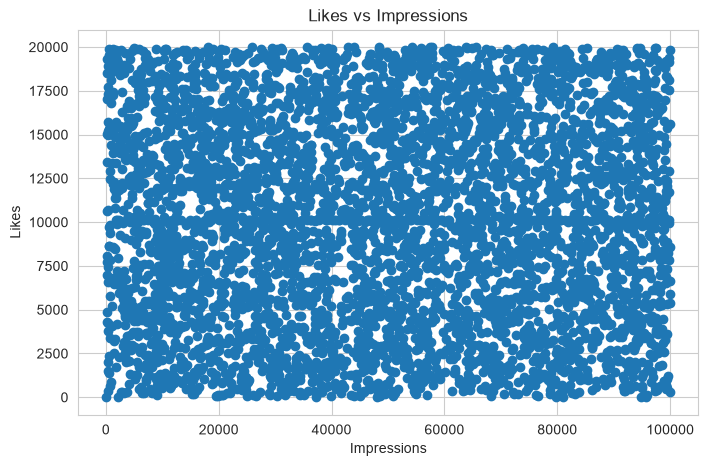

In [95]:
#Chart 1: Scatter plot – Likes vs Impressions
plt.figure(figsize=(8, 5))

plt.scatter(df_clean['impression_count'], df_clean['likes'])

plt.title('Likes vs Impressions')
plt.xlabel('Impressions')
plt.ylabel('Likes')

plt.show()

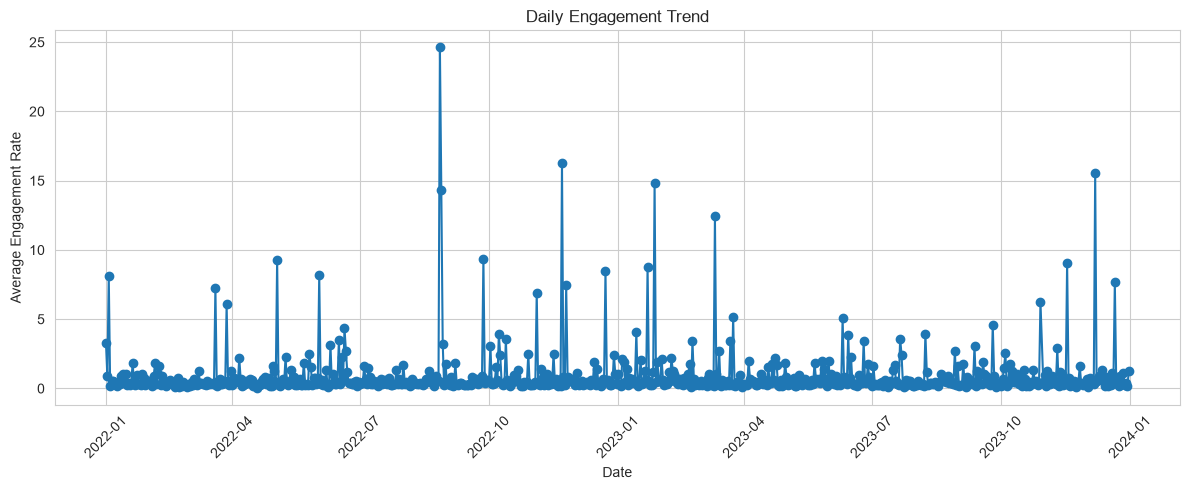

In [96]:
#Chart 2: Line chart – Daily Engagement Trend
df_clean['posted_at'] = pd.to_datetime(
    df_clean['posted_at'], errors='coerce', dayfirst=True
)

daily_engagement = (
    df_clean.dropna(subset=['posted_at'])
    .groupby(df_clean['posted_at'].dt.date)['engagement_rate']
    .mean()
)

plt.figure(figsize=(12, 5))

plt.plot(daily_engagement.index, daily_engagement.values, marker='o')

plt.title('Daily Engagement Trend')
plt.xlabel('Date')
plt.ylabel('Average Engagement Rate')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

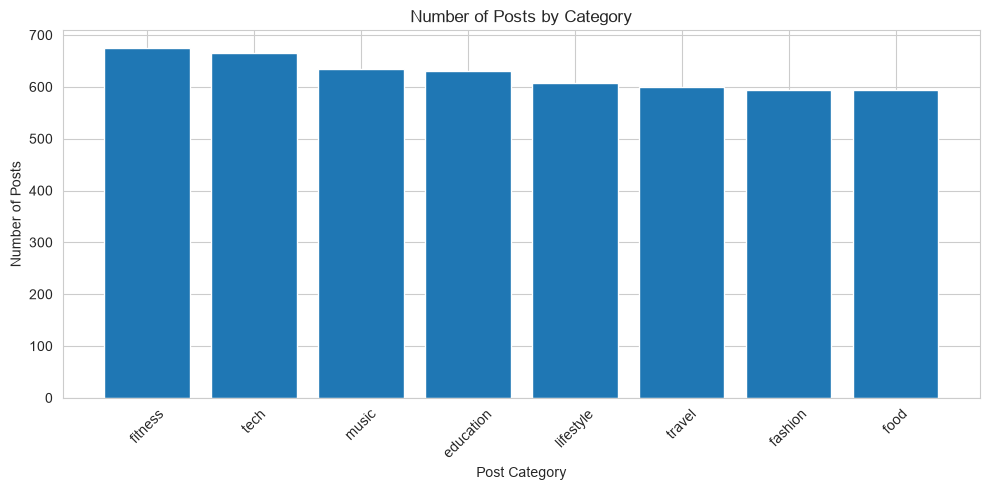

In [97]:
#Chart 3: Bar chart – Posts by Category
category_counts = df_clean['post_category'].value_counts()

plt.figure(figsize=(10, 5))

plt.bar(category_counts.index, category_counts.values)

plt.title('Number of Posts by Category')
plt.xlabel('Post Category')
plt.ylabel('Number of Posts')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

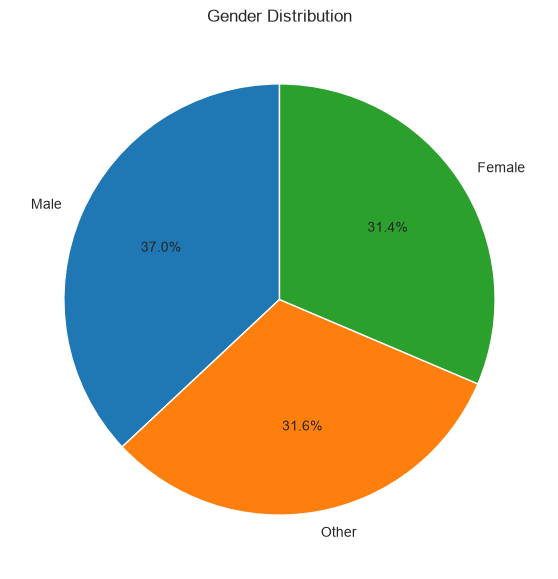

In [98]:
#Chart 4: Pie chart – Gender Distribution
gender_counts = df_clean['gender'].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    gender_counts.values,
    labels=gender_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Gender Distribution')
plt.show()

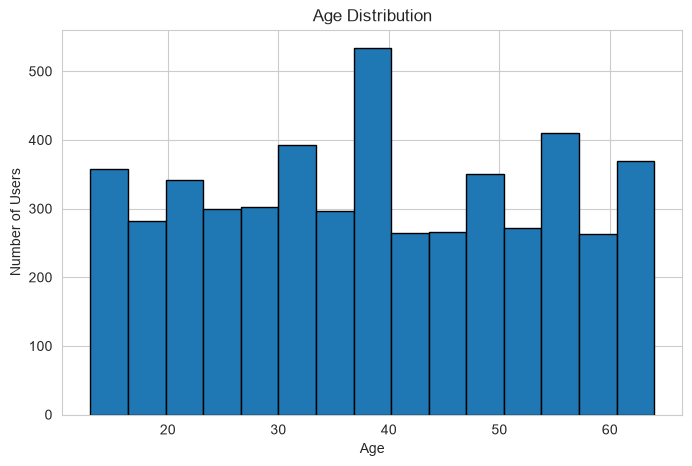

In [99]:
#Chart 5: Histogram – Age Distribution
plt.figure(figsize=(8, 5))

plt.hist(df_clean['age'].dropna(), bins=15, edgecolor='black')

plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Number of Users')

plt.show()

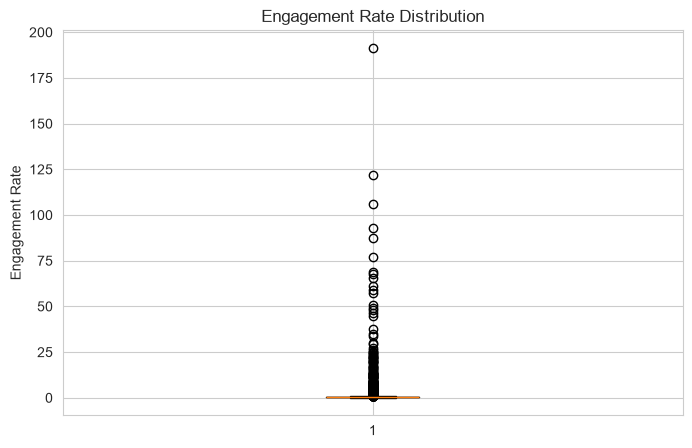

In [100]:
#Chart 6: Box plot – Engagement Rate
plt.figure(figsize=(8, 5))

plt.boxplot(df_clean['engagement_rate'].dropna())

plt.title('Engagement Rate Distribution')
plt.ylabel('Engagement Rate')

plt.show()

In [ ]:
#Seaborn visualizations

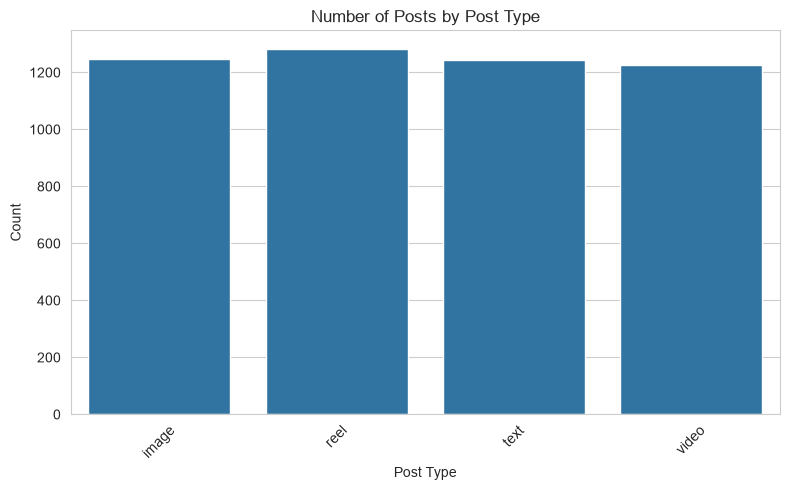

In [101]:
#Chart 7: Count plot – Post Type
plt.figure(figsize=(8, 5))

sns.countplot(data=df_clean, x='post_type')

plt.title('Number of Posts by Post Type')
plt.xlabel('Post Type')
plt.ylabel('Count')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

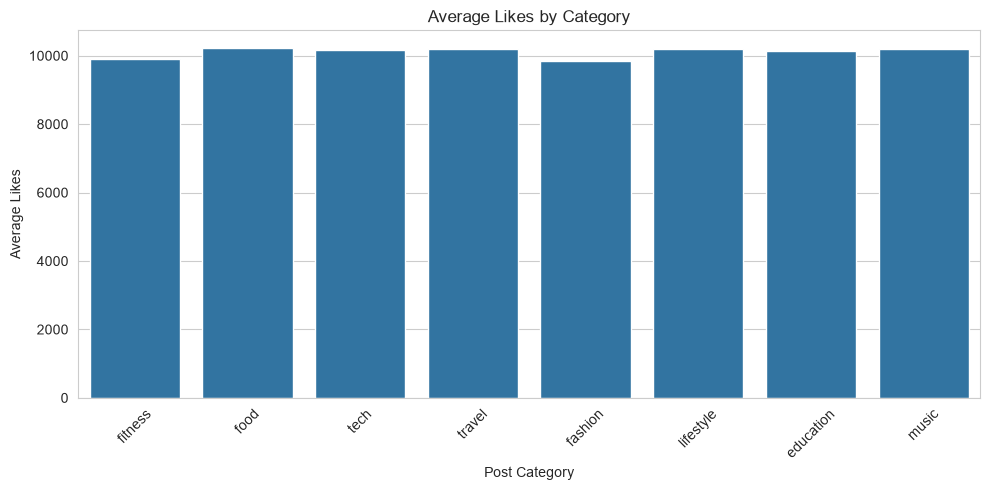

In [103]:
#Chart 8: Bar plot – Average Likes by Category
plt.figure(figsize=(10, 5))

sns.barplot(data=df_clean, x='post_category', y='likes', errorbar=None)

plt.title('Average Likes by Category')
plt.xlabel('Post Category')
plt.ylabel('Average Likes')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

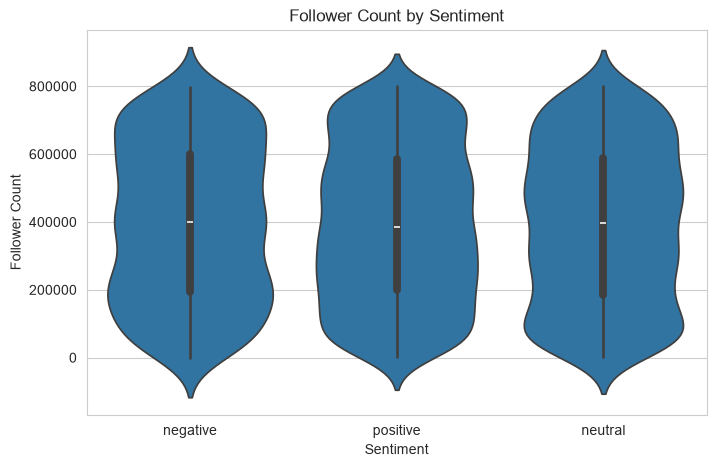

In [117]:
#Chart 9: Violin plot – Followers vs Sentiment
plt.figure(figsize=(8, 5))

sns.violinplot(data=df_clean, x='sentiment', y='follower_count')

plt.title('Follower Count by Sentiment')
plt.xlabel('Sentiment')
plt.ylabel('Follower Count')

plt.show()

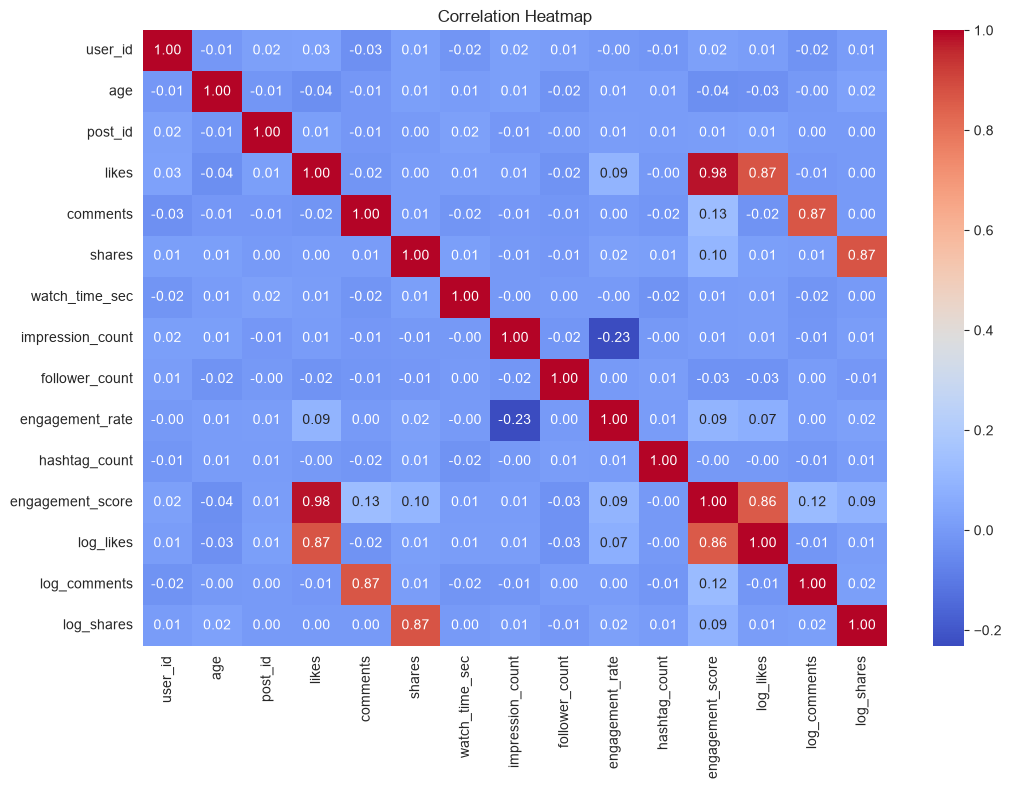

In [104]:
#Chart 10: Heatmap – Correlation Matrix
plt.figure(figsize=(12, 8))

correlation = df_clean.select_dtypes(include=np.number).corr()

sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Heatmap')

plt.show()

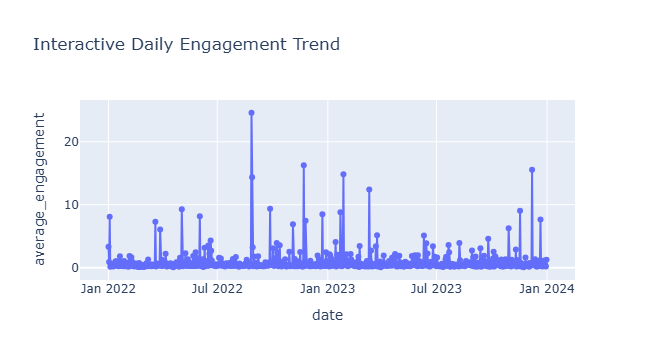

In [108]:
#Chart 11: Interactive Line Chart – Daily Engagement Trend
daily_data = (
    df_clean.dropna(subset=['posted_at'])
    .groupby(df_clean['posted_at'].dt.date, as_index=False)
    .agg(average_engagement=('engagement_rate', 'mean'))
)

daily_data.rename(columns={'posted_at': 'date'}, inplace=True)

fig = px.line(
    daily_data,
    x='date',
    y='average_engagement',
    title='Interactive Daily Engagement Trend',
    markers=True
)

fig.show()

# Final Insights and Findings

In [109]:
#1. Best-performing post type
df.groupby('post_type')['engagement_rate'].mean().sort_values(ascending=False)

post_type
video    1.122365
text     1.064549
image    0.895646
reel     0.783047
Name: engagement_rate, dtype: float64

In [110]:
#2. Best-performing content category
df.groupby('post_category')['engagement_rate'].mean().sort_values(ascending=False)

post_category
food         1.358628
tech         1.160475
lifestyle    1.091019
music        0.888803
fitness      0.865628
education    0.844222
fashion      0.807109
travel       0.702223
Name: engagement_rate, dtype: float64

In [112]:
#3. Country-wise average engagement
df.groupby('country')['engagement_rate'].mean().sort_values(ascending=False)

country
Brazil       1.540704
Australia    1.324339
France       1.146402
UAE          1.112352
Canada       0.916659
UK           0.850966
Japan        0.769623
Germany      0.759000
India        0.655005
USA          0.576580
Name: engagement_rate, dtype: float64

In [113]:
#4. How age affects engagement
df.groupby('age')['engagement_rate'].mean()

age
13.0    0.455583
14.0    1.003067
15.0    0.714170
16.0    1.226848
17.0    0.858763
18.0    0.888391
19.0    0.676687
20.0    0.515541
21.0    0.452752
22.0    0.586786
23.0    0.922448
24.0    2.897327
25.0    1.041681
26.0    0.501467
27.0    0.775328
28.0    0.385081
29.0    1.110432
30.0    1.270129
31.0    0.440684
32.0    0.581710
33.0    1.277557
34.0    0.557236
35.0    1.521596
36.0    0.609569
37.0    0.494109
38.0    1.247501
39.0    0.436184
40.0    0.930504
41.0    1.540070
42.0    1.350772
43.0    0.566439
44.0    0.795102
45.0    0.513521
46.0    0.663994
47.0    1.402015
48.0    1.675878
49.0    0.999235
50.0    1.552627
51.0    2.397295
52.0    0.867426
53.0    0.707924
54.0    1.002622
55.0    2.599106
56.0    0.524008
57.0    0.919751
58.0    0.435130
59.0    0.495578
60.0    0.759586
61.0    0.553854
62.0    1.005127
63.0    1.303909
64.0    0.402533
Name: engagement_rate, dtype: float64

In [114]:
#5. Verified vs non-verified accounts
df.groupby('is_verified')['engagement_rate'].mean()

is_verified
False    0.954744
True     1.054250
Name: engagement_rate, dtype: float64

In [115]:
#6. Device type impact on watch time
df.groupby('device_type')['watch_time_sec'].mean().sort_values(ascending=False)

device_type
mobile     4087.830760
tablet     3979.736429
desktop    3974.792521
Name: watch_time_sec, dtype: float64

In [116]:
#7. Sentiment performance
df.groupby('sentiment')['engagement_rate'].mean().sort_values(ascending=False)

sentiment
negative    1.038486
neutral     0.991170
positive    0.954800
Name: engagement_rate, dtype: float64